# Week 8: Ask simulated users

To start, save a copy to your Drive (File, then Save a copy in Drive), then run the cells in order. It runs on Colab's free CPU runtime. You will need a free Gemini API key from Google AI Studio (aistudio.google.com), and you can add it in the Secrets panel on the left as GEMINI_API_KEY. The outputs below are from one run with four chairs from the week 5 model.

## 1. Setup

This reads your key. If it is not in the Secrets panel, it will ask you to paste it.

In [1]:
import base64, collections, io, json, os, re, sys
import numpy as np, requests
import matplotlib.pyplot as plt
from PIL import Image

def get_key(name):
    """A key from the environment, then from Colab's Secrets panel, then typed in."""
    if os.environ.get(name):
        return os.environ[name]
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        from getpass import getpass
        return getpass(name + ": ")

GEMINI_KEY = get_key("GEMINI_API_KEY")  # free, from aistudio.google.com
MODEL = "gemini-2.5-flash"
print("ready")

ready


## 2. The designs

DESIGNS has four chairs made by the week 5 model. To use your own designs, you can upload the images in the Files panel on the left and open them with Image.open in this cell instead.

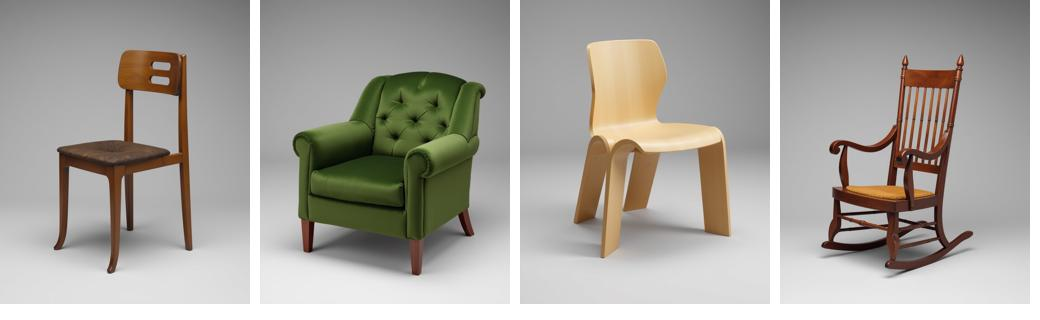

In [2]:
base = "https://raw.githubusercontent.com/chuanenlin/mlfordesign/main/examples/museum-chairs/made/"
DESIGNS = [Image.open(io.BytesIO(requests.get(f"{base}made-{i}.jpg", timeout=60).content)).convert("RGB") for i in range(4)]
row = Image.new("RGB", (4 * 260, 320), "white")
for i, im in enumerate(DESIGNS):
    t = im.copy(); t.thumbnail((250, 320)); row.paste(t, (i * 260, 0))
row

## 3. The personas

Each persona is a short description of a person, and Gemini answers as that person. This is similar to the agents in Park et al.'s paper from today's reading, where each agent starts from a short description. These personas were written for this example and are not real people. The last one has no description, and you can compare the other answers with it. RUNS sets how many times each persona answers.

In [3]:
# Short descriptions written for this example, in the style of Park et al.'s seed memories. They are not real people.
PERSONAS = {
    "Ana": "You are Ana, a barista at the museum café. At closing you stack and wipe all the chairs, and on sunny days you carry them out to the terrace.",
    "Walter": "You are Walter, 74, a retired teacher who visits the museum every week and stays for coffee. You have a stiff back and use armrests to stand up.",
    "Mei": "You are Mei, who comes to the museum with a two-year-old. You need to sit down quickly and keep one hand free.",
    "Sam": "You are Sam, an architecture student who works on a laptop at the café for three or four hours at a time.",
    "Priya": "You are Priya, who buys the museum's furniture. You care about price, how long a chair lasts and whether it can be repaired.",
    "Lukas": "You are Lukas, a tourist on a short visit who stops at the café for ten minutes between galleries.",
    "No description": "You are a visitor at a museum café.",
}
RUNS = 3

## 4. Ask

Each persona picks a chair and gives a reason, RUNS times. The question is in the ask function, and the answers are saved to answers.json.

In [4]:
def image_part(img):
    buf = io.BytesIO(); img.save(buf, format="JPEG", quality=85)
    return {"inline_data": {"mime_type": "image/jpeg", "data": base64.b64encode(buf.getvalue()).decode()}}

ANSWER = {"type": "object", "properties": {"choice": {"type": "integer"}, "reason": {"type": "string"}},
          "required": ["choice", "reason"]}

def ask(persona):
    parts = [{"text": persona + " Here are four chair designs for the museum café."}]
    for i, im in enumerate(DESIGNS):
        parts += [{"text": f"Chair {i + 1}:"}, image_part(im)]
    parts.append({"text": "Speaking as yourself, which chair would you want to sit on at the café, and why? "
                          "Give the chair's number and a reason in two or three sentences."})
    body = {"contents": [{"role": "user", "parts": parts}],
            "generationConfig": {"temperature": 1.0, "responseMimeType": "application/json", "responseSchema": ANSWER}}
    r = requests.post(f"https://generativelanguage.googleapis.com/v1beta/models/{MODEL}:generateContent",
                      headers={"x-goog-api-key": GEMINI_KEY}, json=body, timeout=180)
    r.raise_for_status()
    return json.loads(r.json()["candidates"][0]["content"]["parts"][0]["text"])

answers = []
for name, persona in PERSONAS.items():
    for run in range(RUNS):
        a = ask(persona)
        answers.append({"persona": name, "run": run + 1, **a})
        print(f"{name}, run {run + 1}: chair {a['choice']}. {a['reason']}")
json.dump(answers, open("answers.json", "w"), indent=1)

Ana, run 1: chair 2. I would definitely want to sit on Chair 2. It looks incredibly plush and comfortable, perfect for relaxing with a coffee or tea after a long shift. The armrests and soft upholstery would be a welcome relief.


Ana, run 2: chair 2. As a barista, I'm on my feet all day, so I'd want something truly comfortable to relax in during a break. Chair 2, with its plush cushioning and armrests, looks incredibly inviting and perfect for unwinding.


Ana, run 3: chair 2. I would want to sit on Chair 2 because it looks incredibly comfortable and inviting. The plush upholstery and deep seat would be perfect for a relaxed visit, allowing me to truly unwind with a coffee after a long shift.


Walter, run 1: chair 2. Well now, with my stiff back, I need something comfortable, and those sturdy armrests are essential for helping me stand up after my coffee. Chair 2 looks like just the ticket, offering good support and a bit of plush comfort for a good sit down.


Walter, run 2: chair 2. Chair 2 looks the most comfortable with its plush cushioning, which would be lovely for my back. More importantly, it has sturdy armrests that I can rely on to help me stand up without too much strain.


Walter, run 3: chair 2. This chair has lovely armrests, which are essential for me to push myself up with my stiff back. The plush upholstery also looks wonderfully comfortable for a good long sit with my coffee after walking around the museum all morning.


... (11 outputs left out)

Lukas, run 3: chair 1. I'd pick Chair 1. It looks practical and comfortable enough for a quick sit-down. I only have ten minutes before I need to be back in the galleries, so I don't need anything too plush or inviting to stay longer.


No description, run 1: chair 2. I would choose Chair 2. It looks incredibly comfortable and plush, perfect for relaxing after exploring the museum. The soft velvet and ample padding would make for a very pleasant and indulgent experience while enjoying a drink or snack.


No description, run 2: chair 1. I would choose Chair 1 because it offers a practical and comfortable design suitable for a café setting. Its classic wooden aesthetic would blend well within a museum environment without being overly bulky or distracting, allowing visitors to enjoy a meal or coffee comfortably at a table.


No description, run 3: chair 3. Its modern, minimalist design and ergonomic curves make it appealing for a café setting. It looks both stylish and comfortable enough for a relaxed stop after exploring the museum, without being overly bulky.


## 5. Compare

This prints which chair each persona picked in each run. Then it encodes every reason as an embedding with Gemini's embedding model and compares them with cosine similarity, for two answers by the same persona and for two answers by different personas. In the heatmap, each cell is one pair of answers, and a darker cell means the two answers are more similar.

Chair chosen in each run:
  Ana             [2, 2, 2]
  Walter          [2, 2, 2]
  Mei             [3, 3, 3]
  Sam             [3, 2, 1]
  Priya           [1, 1, 1]
  Lukas           [1, 1, 1]
  No description  [2, 1, 3]


similarity of two answers by the same persona: 0.89
similarity of two answers by different personas: 0.79


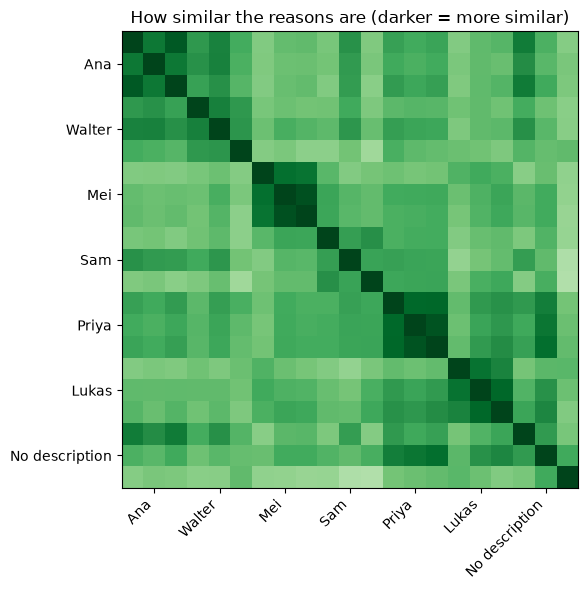

In [5]:
print("Chair chosen in each run:")
for name in PERSONAS:
    print(f"  {name:15s}", [a["choice"] for a in answers if a["persona"] == name])

def embed(texts):
    r = requests.post(f"https://generativelanguage.googleapis.com/v1beta/models/gemini-embedding-001:batchEmbedContents",
                      headers={"x-goog-api-key": GEMINI_KEY},
                      json={"requests": [{"model": "models/gemini-embedding-001", "content": {"parts": [{"text": t}]}} for t in texts]},
                      timeout=120)
    r.raise_for_status()
    E = np.array([e["values"] for e in r.json()["embeddings"]])
    return E / np.linalg.norm(E, axis=1, keepdims=True)

E = embed([a["reason"] for a in answers])
S = E @ E.T
who = [a["persona"] for a in answers]
same = [S[i, j] for i in range(len(who)) for j in range(i + 1, len(who)) if who[i] == who[j]]
other = [S[i, j] for i in range(len(who)) for j in range(i + 1, len(who)) if who[i] != who[j]]
print(f"similarity of two answers by the same persona: {np.mean(same):.2f}")
print(f"similarity of two answers by different personas: {np.mean(other):.2f}")
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(S, vmin=0.5, vmax=1, cmap="Greens")
ticks = [i * RUNS + RUNS // 2 for i in range(len(PERSONAS))]
ax.set_xticks(ticks); ax.set_xticklabels(list(PERSONAS), rotation=45, ha="right")
ax.set_yticks(ticks); ax.set_yticklabels(list(PERSONAS))
ax.set_title("How similar the reasons are (darker = more similar)")
plt.tight_layout(); plt.savefig("similarity.png", dpi=150); plt.show()

## 6. Repeated words

This counts the words used in the most answers. If the same few words come back for every persona, the answers do not tell you much about how these people differ. In your partner tests, you can ask your partner's designers which design they would pick and why, and compare their answers with your simulated users' picks.

In [6]:
STOP = set("a an the and or of to in on for with it is i my me this that would be at as so can its it's chair chairs "
           "one which because want sit café cafe also very more than but have like just".split())
words = collections.Counter()
for a in answers:
    words.update(set(w for w in re.findall(r"[a-z']+", a["reason"].lower()) if w not in STOP and len(w) > 2))
print(f"Words used in the most answers (out of {len(answers)}):")
for w, n in words.most_common(12):
    print(f"  {w:14s} {n}")

Words used in the most answers (out of 21):
  comfortable    15
  looks          15
  plush          10
  design         8
  choose         8
  coffee         7
  armrests       7
  practical      7
  long           6
  after          6
  down           6
  good           6
